# Homework 6

Name: Xiaoyi Kuang  
GitHub username: Xiaoyi-Kuang1

## 1. Tree-Based Methods
### (a)

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, roc_curve
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'font.size': 9, 'figure.dpi': 100})
folder = Path('../data')
train = pd.read_csv(folder / 'aps_failure_training_set.csv', skiprows=20, na_values='na')
test = pd.read_csv(folder / 'aps_failure_test_set.csv', skiprows=20, na_values='na')
x_train = train.drop(columns='class')
x_test = test.drop(columns='class')
y_train = (train['class'] == 'pos').astype(int)
y_test = (test['class'] == 'pos').astype(int)
print('Training shape:', train.shape)
print('Test shape:', test.shape)

Training shape: (60000, 171)
Test shape: (16000, 171)


### (b)(i)

Common methods include mean, median, mode, KNN and regression imputation. I use the median because it is simple and less affected by extreme values. I fill the test set with its own column medians.

In [2]:
imputer = SimpleImputer(strategy='median')
x_train_filled = imputer.fit_transform(x_train)
test_imputer = SimpleImputer(strategy='median')
x_test_filled = test_imputer.fit_transform(x_test)
x_plot = pd.DataFrame(x_train_filled, columns=x_train.columns)
print('Missing training values:', x_train.isna().sum().sum())
print('Missing test values:', x_test.isna().sum().sum())
print('Missing values after imputation:', np.isnan(x_train_filled).sum() + np.isnan(x_test_filled).sum())

Missing training values: 850015
Missing test values: 228680
Missing values after imputation: 0


### (b)(ii)

In [3]:
cv_values = x_plot.std(ddof=1) / x_plot.mean().replace(0, np.nan)
cv_table = cv_values.rename('CV').reset_index().rename(columns={'index': 'Feature'})
parts = [cv_table.iloc[i:i + 34].reset_index(drop=True) for i in range(0, 170, 34)]
display(pd.concat(parts, axis=1).round(3))

,Feature,CV,Feature,CV,Feature,CV,Feature,CV,Feature,CV
0,aa_000,2.451,ay_002,39.249,bh_000,2.629,cn_003,4.192,dh_000,123.216
1,ab_000,10.383,ay_003,28.735,bi_000,3.022,cn_004,2.621,di_000,11.826
2,ac_000,2.310,ay_004,33.752,bj_000,3.576,cn_005,2.345,dj_000,117.494
3,ad_000,244.323,ay_005,12.525,bk_000,0.820,cn_006,3.163,dk_000,37.039
4,ae_000,24.200,ay_006,3.053,bl_000,0.871,cn_007,6.335,dl_000,39.739
5,af_000,19.471,ay_007,3.314,bm_000,0.849,cn_008,9.734,dm_000,36.261
6,ag_000,92.918,ay_008,3.816,bn_000,0.836,cn_009,34.272,dn_000,2.888
7,ag_001,35.249,ay_009,84.734,bo_000,0.792,co_000,244.507,do_000,2.166
8,ag_002,17.566,az_000,9.406,bp_000,0.753,cp_000,13.933,dp_000,2.022
9,ag_003,8.647,az_001,7.721,bq_000,0.719,cq_000,2.405,dq_000,22.030


### (b)(iii)

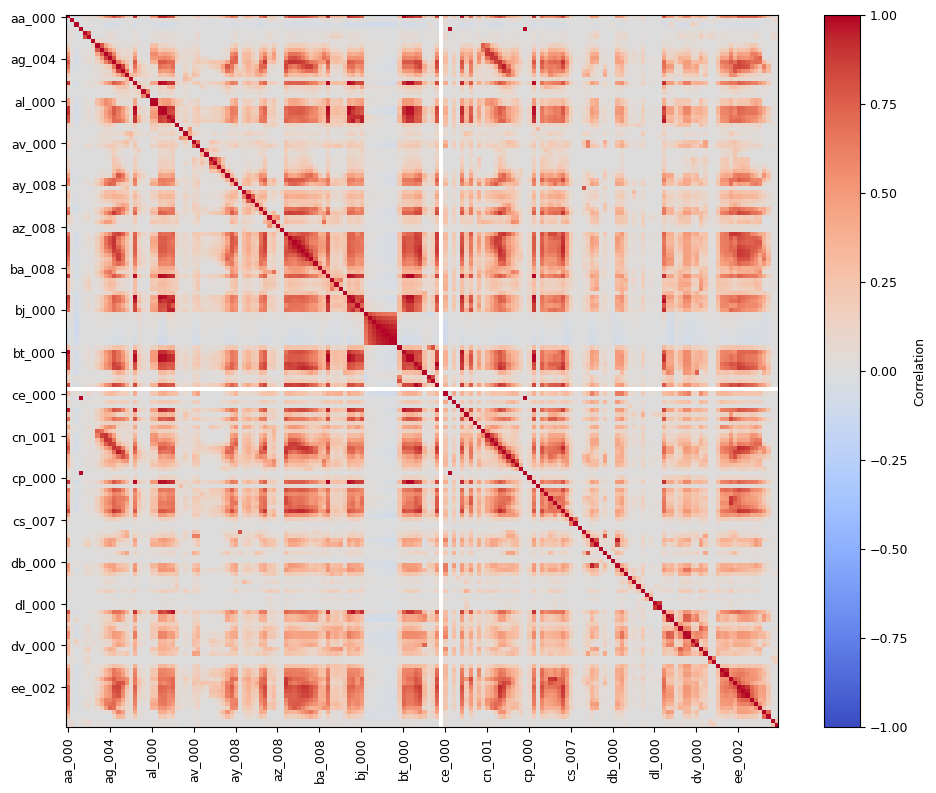

In [4]:
corr = x_plot.corr()
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(0, 170, 10))
ax.set_yticks(range(0, 170, 10))
ax.set_xticklabels(x_train.columns[::10], rotation=90)
ax.set_yticklabels(x_train.columns[::10])
fig.colorbar(image, ax=ax, label='Correlation')
plt.tight_layout()
plt.show()

### (b)(iv)
For the scatter matrix, I use all 1,000 positive cases and 5,000 randomly selected negative cases. I use symlog scales because the values are very large.

Selected features: cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000, au_000


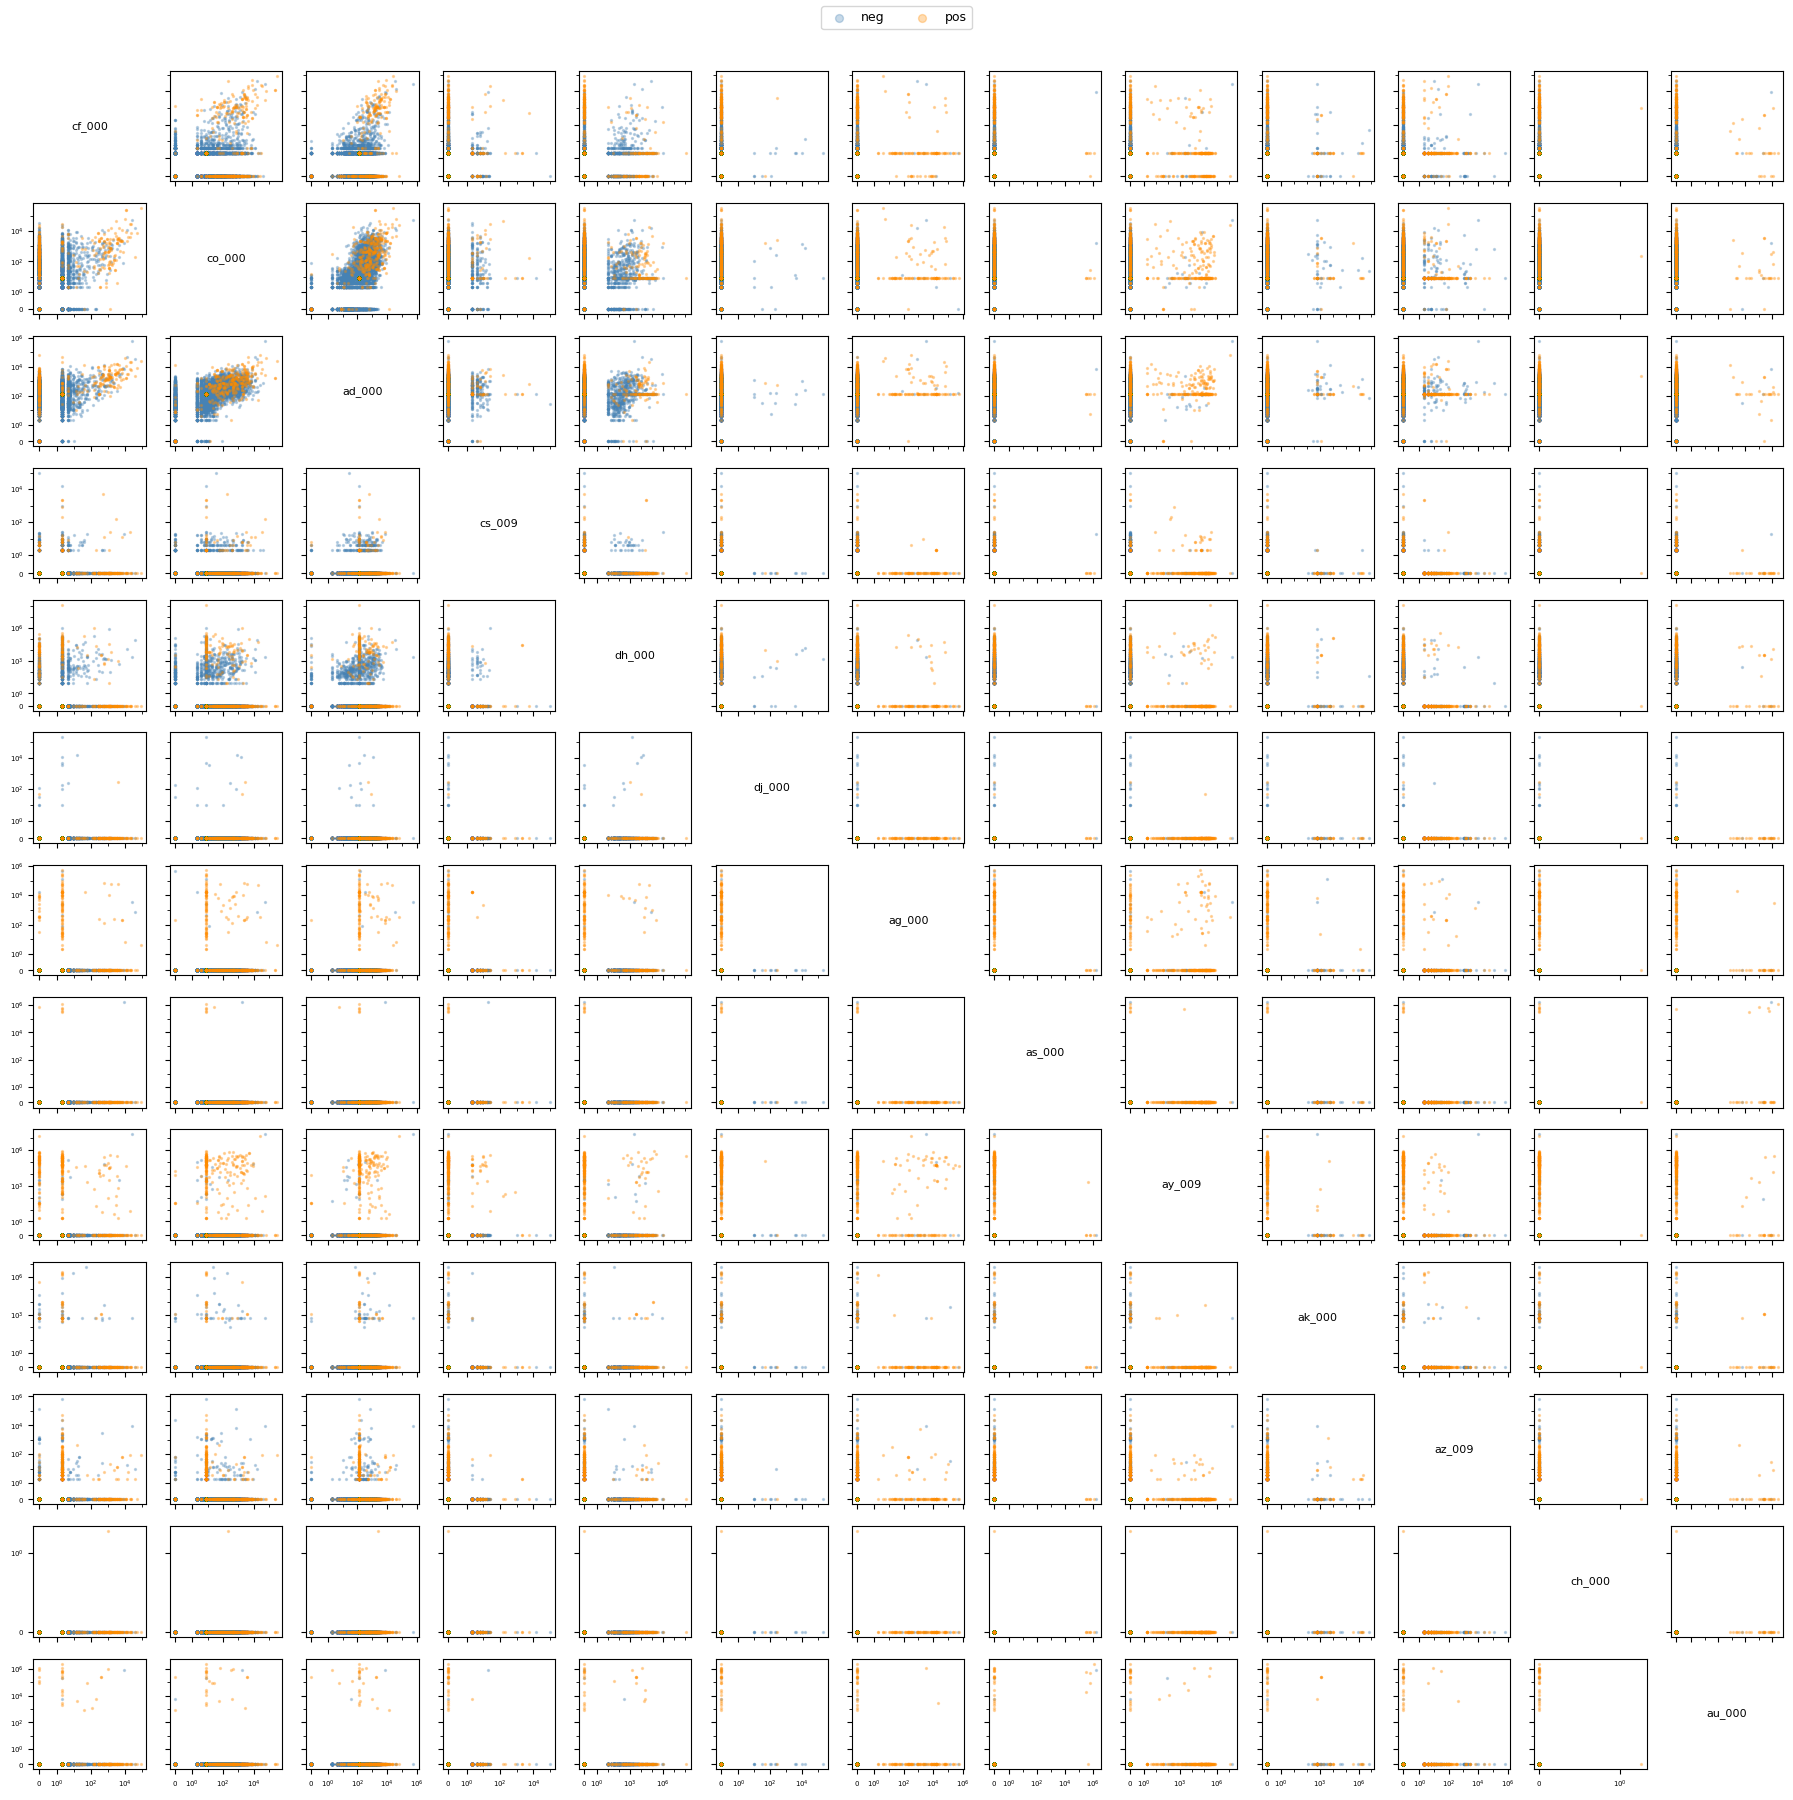

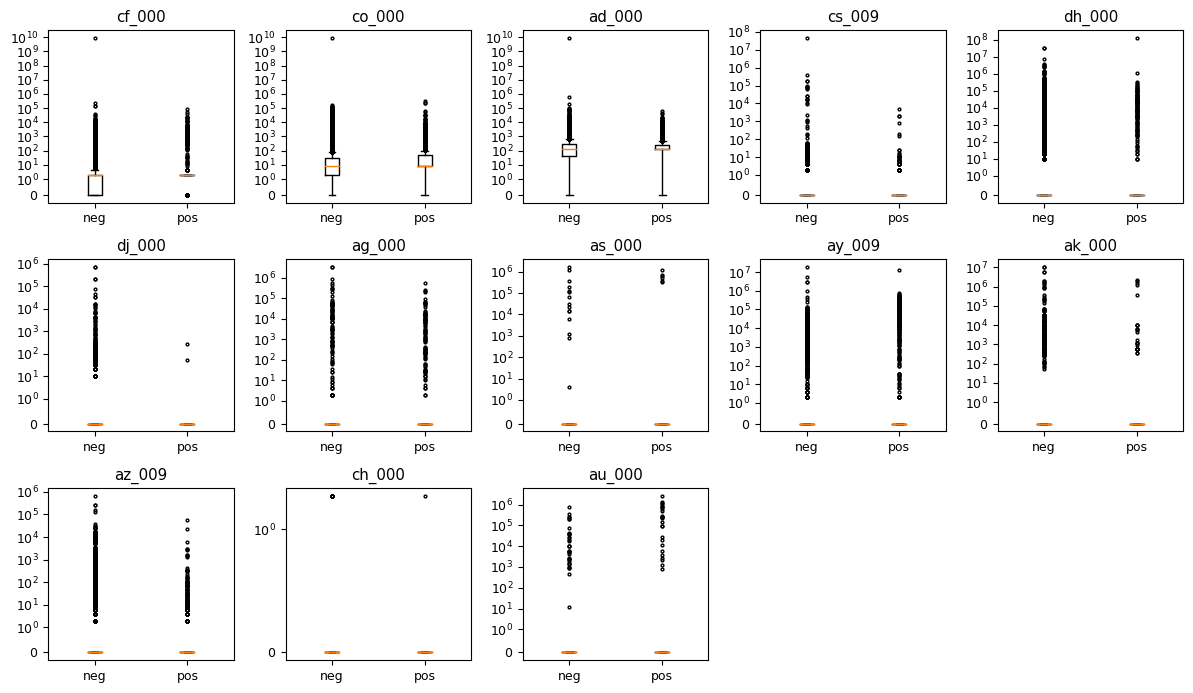

In [5]:
selected = cv_values.nlargest(13).index.tolist()
print('Selected features:', ', '.join(selected))
neg = x_plot.loc[y_train == 0].sample(5000, random_state=1)
pos = x_plot.loc[y_train == 1]
fig, axes = plt.subplots(13, 13, figsize=(18, 18), sharex='col', sharey='row')
for i in range(13):
    for j in range(13):
        ax = axes[i, j]
        x_name = selected[j]
        y_name = selected[i]
        if i == j:
            ax.text(0.5, 0.5, x_name, ha='center', va='center', transform=ax.transAxes, fontsize=8)
            ax.axis('off')
        else:
            ax.scatter(neg[x_name], neg[y_name], s=2, alpha=0.3, color='steelblue', label='neg')
            ax.scatter(pos[x_name], pos[y_name], s=2, alpha=0.3, color='darkorange', label='pos')
        ax.set_xscale('symlog', linthresh=1)
        ax.set_yscale('symlog', linthresh=1)
        ax.xaxis.get_major_locator().set_params(numticks=4)
        ax.yaxis.get_major_locator().set_params(numticks=4)
        ax.tick_params(labelsize=5)
handles, labels = axes[0, 1].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, markerscale=4)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for ax, name in zip(axes.flat, selected):
    neg_values = x_plot.loc[y_train == 0, name]
    pos_values = x_plot.loc[y_train == 1, name]
    ax.boxplot([neg_values, pos_values], labels=['neg', 'pos'], flierprops={'markersize': 2})
    ax.set_yscale('symlog', linthresh=1)
    ax.set_title(name)
for ax in axes.flat[13:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

No. The two classes overlap a lot in the scatter matrix. Some box plots show different distributions, but these plots alone cannot establish statistical significance.

### (b)(v)

In [6]:
counts = pd.DataFrame({'Train': train['class'].value_counts(), 'Test': test['class'].value_counts()}).loc[['neg', 'pos']]
counts['Total'] = counts['Train'] + counts['Test']
display(counts)
print('Training negative-to-positive ratio:', counts.loc['neg', 'Train'] / counts.loc['pos', 'Train'])

,Train,Test,Total
neg,59000,15625,74625
pos,1000,375,1375


Training negative-to-positive ratio: 59.0


Yes, it is imbalanced. The training set has 59 negative cases for each positive case. Only 1.67% of training cases are positive.

### (c)

I use 200 trees without class weights. For all models, positive means APS failure and the classification threshold is 0.5. Confusion matrix rows are actual classes and columns are predicted classes, in the order neg, pos.

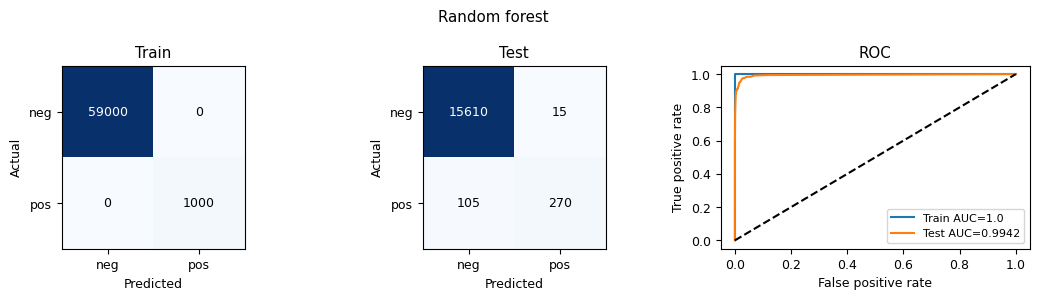

,Error,AUC,Positive recall
Set,,,
Train,0.0000,1.000000,1.00
Test,0.0075,0.994217,0.72


OOB error: 0.006067


In [7]:
def report(model, x_train, x_test, y_train, y_test, title):
    rows = []
    fig, axes = plt.subplots(1, 3, figsize=(11, 3))
    for i, (name, x, y) in enumerate([('Train', x_train, y_train), ('Test', x_test, y_test)]):
        prob = model.predict_proba(x)[:, 1]
        pred = (prob > 0.5).astype(int)
        matrix = confusion_matrix(y, pred, labels=[0, 1])
        error = 1 - accuracy_score(y, pred)
        auc = roc_auc_score(y, prob)
        rows.append([name, error, auc, matrix[1, 1] / matrix[1].sum()])
        axes[i].imshow(matrix, cmap='Blues')
        for r in range(2):
            for c in range(2):
                axes[i].text(c, r, str(matrix[r, c]), ha='center', va='center', color='white' if matrix[r, c] > matrix.max() / 2 else 'black')
        axes[i].set(xticks=[0, 1], yticks=[0, 1], xticklabels=['neg', 'pos'], yticklabels=['neg', 'pos'], xlabel='Predicted', ylabel='Actual', title=name)
        fpr, tpr, _ = roc_curve(y, prob)
        axes[2].plot(fpr, tpr, label=name + ' AUC=' + str(round(auc, 4)))
    axes[2].plot([0, 1], [0, 1], 'k--')
    axes[2].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC')
    axes[2].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    result = pd.DataFrame(rows, columns=['Set', 'Error', 'AUC', 'Positive recall']).set_index('Set')
    display(result.round(6))
    return result

forest = RandomForestClassifier(n_estimators=200, max_features='sqrt', oob_score=True, random_state=1, n_jobs=4)
forest.fit(x_train_filled, y_train)
forest_result = report(forest, x_train_filled, x_test_filled, y_train, y_test, 'Random forest')
print('OOB error:', round(1 - forest.oob_score_, 6))

OOB error is 0.006067, compared with test error 0.007500. The OOB estimate is slightly lower than the test error.

### (d)

Common methods include class weights, majority-class undersampling and changing the classification threshold. I use `class_weight='balanced'`, so each positive case gets 59 times the weight of a negative case.

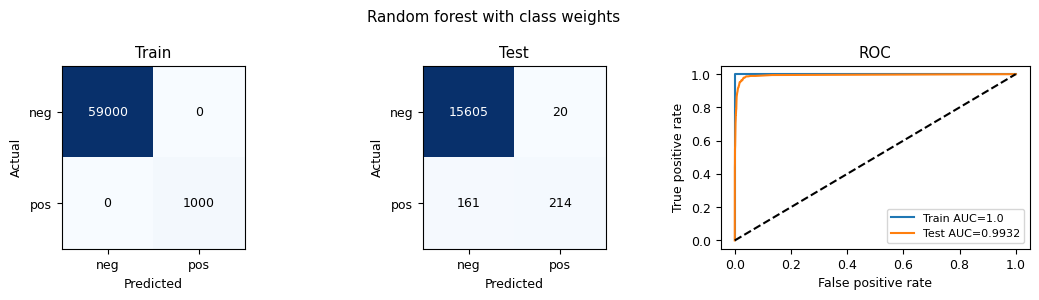

,Error,AUC,Positive recall
Set,,,
Train,0.000000,1.000000,1.000000
Test,0.011312,0.993201,0.570667


OOB error: 0.007617


In [8]:
balanced_forest = RandomForestClassifier(n_estimators=200, max_features='sqrt', class_weight='balanced', oob_score=True, random_state=1, n_jobs=4)
balanced_forest.fit(x_train_filled, y_train)
balanced_result = report(balanced_forest, x_train_filled, x_test_filled, y_train, y_test, 'Random forest with class weights')
print('OOB error:', round(1 - balanced_forest.oob_score_, 6))

The weighted forest has OOB error 0.007617 and test error 0.011312. Compared with (c), test error increases from 0.007500 and positive recall falls from 0.7200 to 0.5707. Class weighting does not improve this model on the test set.

### (e)

I use XGBoost with logistic loss and L1 regularization. I select alpha by the lowest error in stratified 5-fold CV. No class weights or resampling are used.

,alpha,CV error
0,0,0.005917
1,0.01,0.005867
2,0.1,0.005967
3,1,0.006000
4,10,0.006667


Selected alpha: 0.01


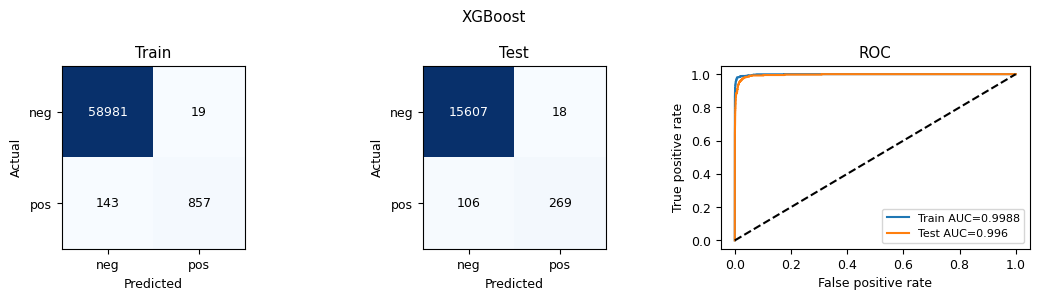

,Error,AUC,Positive recall
Set,,,
Train,0.00270,0.998774,0.857000
Test,0.00775,0.995955,0.717333


In [9]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
boost = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, objective='binary:logistic', reg_lambda=0, tree_method='hist', eval_metric='logloss', random_state=1, n_jobs=4)
boost_model = Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', boost)])
params = {'model__reg_alpha': [0, 0.01, 0.1, 1, 10]}
boost_search = GridSearchCV(boost_model, params, cv=folds, scoring='accuracy', n_jobs=1)
boost_search.fit(x_train, y_train)
cv_result = pd.DataFrame({'alpha': boost_search.cv_results_['param_model__reg_alpha'], 'CV error': 1 - boost_search.cv_results_['mean_test_score']})
display(cv_result)
print('Selected alpha:', boost_search.best_params_['model__reg_alpha'])
boost_result = report(boost_search.best_estimator_, x_train, pd.DataFrame(x_test_filled, columns=x_train.columns), y_train, y_test, 'XGBoost')

The selected alpha is 0.01. The 5-fold CV error is 0.005867, lower than the test error of 0.007750. This CV error is also used to select alpha, so it may be optimistic.

### (f)

SMOTE is applied only within each CV training fold. Validation and test sets are not resampled.

,alpha,CV error
0,0,0.014783
1,0.01,0.014900
2,0.1,0.014883
3,1,0.015217
4,10,0.015583


Selected alpha: 0


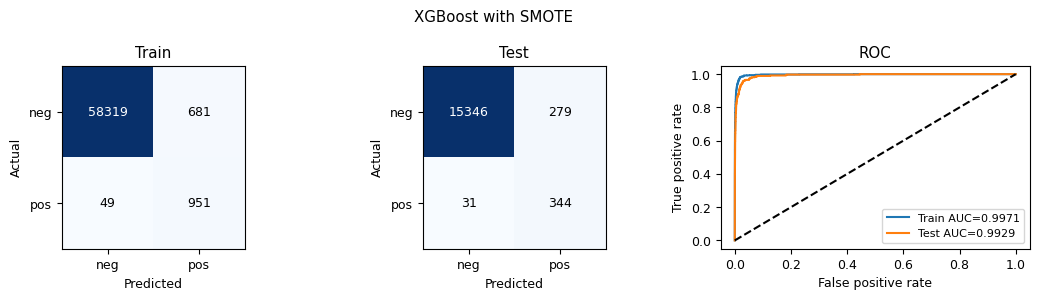

,Error,AUC,Positive recall
Set,,,
Train,0.012167,0.997117,0.951000
Test,0.019375,0.992860,0.917333


In [10]:
smote_boost = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, objective='binary:logistic', reg_lambda=0, tree_method='hist', eval_metric='logloss', random_state=1, n_jobs=4)
smote_model = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('smote', SMOTE(random_state=1)), ('model', smote_boost)])
smote_search = GridSearchCV(smote_model, params, cv=folds, scoring='accuracy', n_jobs=1)
smote_search.fit(x_train, y_train)
cv_result = pd.DataFrame({'alpha': smote_search.cv_results_['param_model__reg_alpha'], 'CV error': 1 - smote_search.cv_results_['mean_test_score']})
display(cv_result)
print('Selected alpha:', smote_search.best_params_['model__reg_alpha'])
smote_result = report(smote_search.best_estimator_, x_train, pd.DataFrame(x_test_filled, columns=x_train.columns), y_train, y_test, 'XGBoost with SMOTE')

The selected alpha is 0. With SMOTE, the CV error is 0.014783 and the test error is 0.019375. Compared with (e), the positive recall goes up from 0.7173 to 0.9173, so there are fewer false negatives (106 down to 31). But there are more false positives (18 up to 279), so the test error is higher and the AUC is a little lower (0.995955 to 0.992860).

## 2. ISLR Chapter 6, Exercise 3

(a) **iv.** Training RSS decreases or stays the same. A larger s allows more coefficient values, so the minimum RSS cannot increase.

(b) **ii.** Test RSS typically decreases and then increases. Less shrinkage first reduces underfitting, but having too much flexibility can cause overfit.

(c) **iii.** Variance generally increases as the model becomes more flexible.

(d) **iv.** Squared bias generally decreases because the constraint becomes weaker.

(e) **v.** Irreducible error stays constant because it comes from noise in the data.

## 3. ISLR Chapter 6, Exercise 5

Let $x_i=x_{i1}=x_{i2}$. Assume $x_{11}+x_{21}=0$, $x_{12}+x_{22}=0$ and $y_1+y_2=0$, so the intercept is zero.

(a) Ridge minimizes
$$\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2).$$

(b) Since the two predictors are identical, the RSS only depends on $\beta_1+\beta_2$. For a fixed sum, $\beta_1^2+\beta_2^2$ is smallest when the two coefficients are equal. Therefore, for $\lambda>0$, $\hat\beta_1=\hat\beta_2$.

(c) Lasso minimizes
$$\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|).$$

(d) Lasso can have more than one solution. Suppose the best coefficient sum is $s\ne0$. The pairs $(s,0)$, $(0,s)$ and $(s/2,s/2)$ all give the same predictions and the same penalty $\lambda|s|$. Any split of $s$ between two coefficients with the same sign also gives the same result. If the best sum is zero and $\lambda>0$, both coefficients are zero.

## 4. ISLR 8.4.5

**Majority vote: Red.** Six trees give a red probability above 0.5 and four give a probability below 0.5.

**Average probability: Green.** The mean red probability is $4.5/10=0.45<0.5$.

## 5. ISLR 9.7.3

(a), (b), (d), (e) The left plot shows the observations, optimal boundary, margins and support vectors.

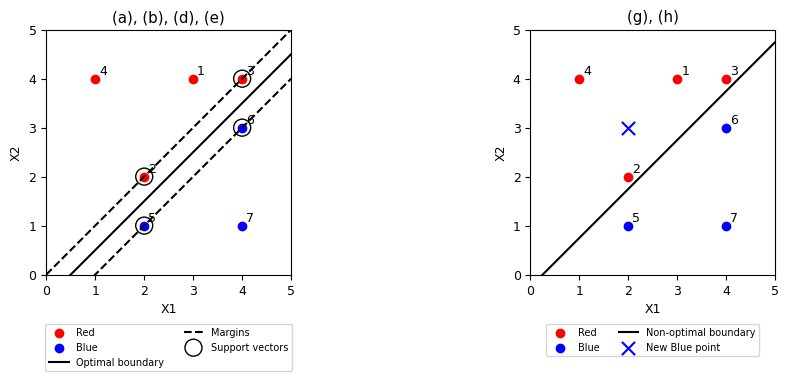

In [11]:
points = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
line = np.linspace(0, 5, 100)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax in axes:
    ax.scatter(points[:4, 0], points[:4, 1], color='red', label='Red')
    ax.scatter(points[4:, 0], points[4:, 1], color='blue', label='Blue')
    for i, (x1, x2) in enumerate(points):
        ax.annotate(str(i + 1), (x1 + 0.08, x2 + 0.08))
    ax.set(xlim=(0, 5), ylim=(0, 5), xlabel='X1', ylabel='X2')
    ax.set_aspect('equal')
axes[0].plot(line, line - 0.5, 'k-', label='Optimal boundary')
axes[0].plot(line, line, 'k--', label='Margins')
axes[0].plot(line, line - 1, 'k--')
support = points[[1, 2, 4, 5]]
axes[0].scatter(support[:, 0], support[:, 1], s=150, facecolors='none', edgecolors='black', label='Support vectors')
axes[0].set_title('(a), (b), (d), (e)')
axes[1].plot(line, line - 0.25, 'k-', label='Non-optimal boundary')
axes[1].scatter(2, 3, color='blue', marker='x', s=90, label='New Blue point')
axes[1].set_title('(g), (h)')
for ax in axes:
    ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout()
plt.show()

(b) The optimal boundary is $0.5-X_1+X_2=0$, or $X_2=X_1-0.5$.

(c) $\beta_0=0.5$, $\beta_1=-1$, $\beta_2=1$. Classify as Red if $0.5-X_1+X_2>0$, and Blue otherwise.

(d) The margin lines are $X_2=X_1$ and $X_2=X_1-1$. The perpendicular distance from the boundary to either margin is $0.5/\sqrt{2}$.

(e) The support vectors are observations 2, 3, 5 and 6.

(f) Observation 7, $(4,1)$, is far from the margin. A small movement that keeps it outside the margin does not change the boundary.

(g) $X_2=X_1-0.25$ separates the original classes, but its smallest margin is smaller.

(h) Add a Blue point at $(2,3)$. It lies inside the convex hull of the Red points, so no straight line can separate the two classes.